# Stock Performance & Risk Analysis

## Question
Which stocks gave the best return for the amount of risk taken
over the last 5 years?

## Stocks analyzed
- AAPL (Apple) – Technology
- JPM (JPMorgan) – Finance
- XOM (ExxonMobil) – Energy
- TSLA (Tesla) – Automotive / Technology
- JNJ (Johnson & Johnson) – Healthcare
- SPY (S&P 500 ETF) – Benchmark

## Time period
November 2021 – November 2026 (daily data)

## Tools
Python, pandas, yfinance, matplotlib

## Plan
1. Download and clean the data
2. Calculate returns
3. Visualize performance
4. Measure risk (volatility, Sharpe ratio, drawdown)
5. Check correlations
6. Draw conclusions

In [7]:
# Step 1: Install the yfinance library if it is not already installed
!pip install yfinance

# Step 2: Import the necessary libraries
import pandas as pd
import yfinance as yf

# Step 3: Define the stock tickers we want to analyze
# AAPL: Apple, JPM: JPMorgan, XOM: ExxonMobil, TSLA: Tesla, JNJ: Johnson & Johnson, SPY: S&P 500 ETF (Benchmark)
tickers = ['AAPL', 'JPM', 'XOM', 'TSLA', 'JNJ', 'SPY']

# Step 4: Download 5 years of daily historical data for these tickers
# We use '5y' for the 5-year period
print("Downloading historical stock data...")
data = yf.download(tickers, period='5y', interval='1d')

# Step 5: Extract the 'Close' price column for each stock
# Under yfinance's current defaults, the 'Close' column already contains the adjusted closing prices
adj_close_df = data['Close']

# Step 6: Display basic information and the first few rows of our DataFrame
print("\nData download complete! Here is a preview of the DataFrame:")
display(adj_close_df.head())

# Step 7: Check for any missing values
print("\nMissing values count per stock:")
print(adj_close_df.isnull().sum())


/tmp/ipykernel_778/4132785587.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period='5y', interval='1d')
[*********************100%***********************]  6 of 6 completed


Data download complete! Here is a preview of the DataFrame:


Ticker,AAPL,JNJ,JPM,SPY,TSLA,XOM
Date,,,,,,
2021-11-22,157.164062,139.797195,145.173111,437.319336,385.623322,51.986465
2021-11-23,157.544754,140.663818,148.644577,437.899261,369.676666,53.355656
2021-11-24,158.061981,140.269882,147.478592,439.068359,372.000000,53.651455
2021-11-26,153.054871,139.359528,143.035507,429.275787,360.640015,51.766731
2021-11-29,156.402756,139.840942,142.417145,434.541504,378.996674,52.054089



Missing values count per stock:
Ticker
AAPL    0
JNJ     0
JPM     0
SPY     0
TSLA    0
XOM     0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1255 entries, 2021-11-22 to 2026-11-20
Data columns (total 30 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1255 non-null   float64
 1   (Close, JNJ)    1255 non-null   float64
 2   (Close, JPM)    1255 non-null   float64
 3   (Close, SPY)    1255 non-null   float64
 4   (Close, TSLA)   1255 non-null   float64
 5   (Close, XOM)    1255 non-null   float64
 6   (High, AAPL)    1255 non-null   float64
 7   (High, JNJ)     1255 non-null   float64
 8   (High, JPM)     1255 non-null   float64
 9   (High, SPY)     1255 non-null   float64
 10  (High, TSLA)    1255 non-null   float64
 11  (High, XOM)     1255 non-null   float64
 12  (Low, AAPL)     1255 non-null   float64
 13  (Low, JNJ)      1255 non-null   float64
 14  (Low, JPM)      1255 non-null   float

```markdown
## Handling Missing Data

In financial time-series data, missing values can sometimes occur due to holidays, market closures, or data feed glitches. There are three common ways to handle them:
1. **Check for missing values**: Identify which columns (stocks) and dates have missing entries.
2. **Forward Fill (`ffill`)**: Replace a missing value with the previous day's price. This is highly recommended for stock data because the last known price is the best estimate of the current price.
3. **Drop rows (`dropna`)**: Remove any row that contains missing values. This is simple, but we might lose some valid data from other stocks on that day.
```

In [8]:
# Step 1: Check for missing values in each column
print("--- 1. Checking for Missing Values ---")
missing_counts = adj_close_df.isnull().sum()
print(missing_counts)

# Step 2: Let's demonstrate how we would handle them if we found any.
# We will create a copy of our DataFrame to practice on
clean_df = adj_close_df.copy()

# Method A: Forward Fill (Best for stock prices)
# This fills any missing value with the last available price before it.
clean_df_filled = clean_df.ffill()

# Method B: Backward Fill (Optional)
# In case there's a missing value at the very beginning of the dataset,
# we can follow up with a backward fill (bfill) to fill it with the next day's price.
clean_df_filled = clean_df_filled.bfill()

# Method C: Drop missing values
# This simply deletes any row that has at least one missing stock price.
clean_df_dropped = clean_df.dropna()

# Step 3: Verify the cleaning process
print("\n--- 2. Verifying clean DataFrame (using Forward Fill) ---")
print(clean_df_filled.isnull().sum())

--- 1. Checking for Missing Values ---
Ticker
AAPL    0
JNJ     0
JPM     0
SPY     0
TSLA    0
XOM     0
dtype: int64

--- 2. Verifying clean DataFrame (using Forward Fill) ---
Ticker
AAPL    0
JNJ     0
JPM     0
SPY     0
TSLA    0
XOM     0
dtype: int64


```markdown
## Why We Use Returns Instead of Raw Prices

When comparing different financial assets, we almost always analyze **returns** rather than **raw prices** for several key reasons:

1. **Comparability (Normalization)**: A stock priced at \$400 (like TSLA) and a stock priced at \$150 (like AAPL) cannot be compared directly by their dollar moves. A \$10 increase is a major 6.67% gain for AAPL, but only a 2.5% gain for TSLA. Returns normalize the scale so we can compare them side-by-side.
2. **Stationarity**: Raw price series are typically non-stationary (they tend to trend up or down over time), making statistical modeling difficult. Percentage changes (returns) fluctuate around a stable mean, which is much better for statistical analysis and machine learning models.
3. **Investment Neutrality**: Returns represent the change per dollar invested. Whether you invest \$1,000 in a stock that costs \$10 or a stock that costs \$1,000, your final profit or loss depends entirely on the percentage return.

### Definitions:
* **Daily Return**: The percentage change from yesterday's price to today's price.
* **Cumulative Return**: The total return earned on an investment over a period, showing how a single dollar invested at the start would grow over time.
```

In [9]:
# Step 1: Calculate daily percentage returns
# pct_change() calculates: (Price_today - Price_yesterday) / Price_yesterday
daily_returns = adj_close_df.pct_change()

# Step 2: Calculate cumulative returns
# Formula: Cumulative Return = (1 + Daily_Return_1) * (1 + Daily_Return_2) * ... - 1
# We use (1 + daily_returns).cumprod() to calculate the running growth factor, then subtract 1
cumulative_returns = (1 + daily_returns).cumprod() - 1

# Step 3: Display daily returns preview
print("--- Daily Percentage Returns (First 5 Rows) ---")
# Note: The first row will be NaN because there is no prior day to calculate a change from
display(daily_returns.head())

# Step 4: Display cumulative returns preview
print("\n--- Cumulative Returns (First 5 Rows) ---")
display(cumulative_returns.head())

# Step 5: Display final total cumulative returns for each stock
print("\n--- Total Cumulative Returns Over 5 Years ---")
final_cumulative = cumulative_returns.iloc[-1] * 100
print(final_cumulative.map("{:.2f}%".format))

--- Daily Percentage Returns (First 5 Rows) ---


Ticker,AAPL,JNJ,JPM,SPY,TSLA,XOM
Date,,,,,,
2021-11-22,NaN,NaN,NaN,NaN,NaN,NaN
2021-11-23,0.002422,0.006199,0.023913,0.001326,-0.041353,0.026337
2021-11-24,0.003283,-0.002801,-0.007844,0.002670,0.006285,0.005544
2021-11-26,-0.031678,-0.006490,-0.030127,-0.022303,-0.030538,-0.035129
2021-11-29,0.021874,0.003454,-0.004323,0.012267,0.050900,0.005551



--- Cumulative Returns (First 5 Rows) ---


Ticker,AAPL,JNJ,JPM,SPY,TSLA,XOM
Date,,,,,,
2021-11-22,NaN,NaN,NaN,NaN,NaN,NaN
2021-11-23,0.002422,0.006199,0.023913,0.001326,-0.041353,0.026337
2021-11-24,0.005713,0.003381,0.015881,0.003999,-0.035328,0.032027
2021-11-26,-0.026146,-0.003131,-0.014725,-0.018393,-0.064787,-0.004227
2021-11-29,-0.004844,0.000313,-0.018984,-0.006352,-0.017184,0.001301



--- Total Cumulative Returns Over 5 Years ---
Ticker
AAPL    119.33%
JNJ      94.32%
JPM     115.20%
SPY      59.12%
TSLA     -9.56%
XOM     209.53%
Name: 2026-11-20 00:00:00, dtype: object


```markdown
## Visualizing the Growth of $1

To compare how each stock actually performed over time, we can simulate investing $1 in each of them on day one.

We calculate the value of this investment over time as:
$$\text{Investment Value} = 1 + \text{Cumulative Return}$$

If a stock has a cumulative return of `1.19` (or 119%), our $1 investment has grown to `$2.19` ($1 principal + $1.19 gain).
```

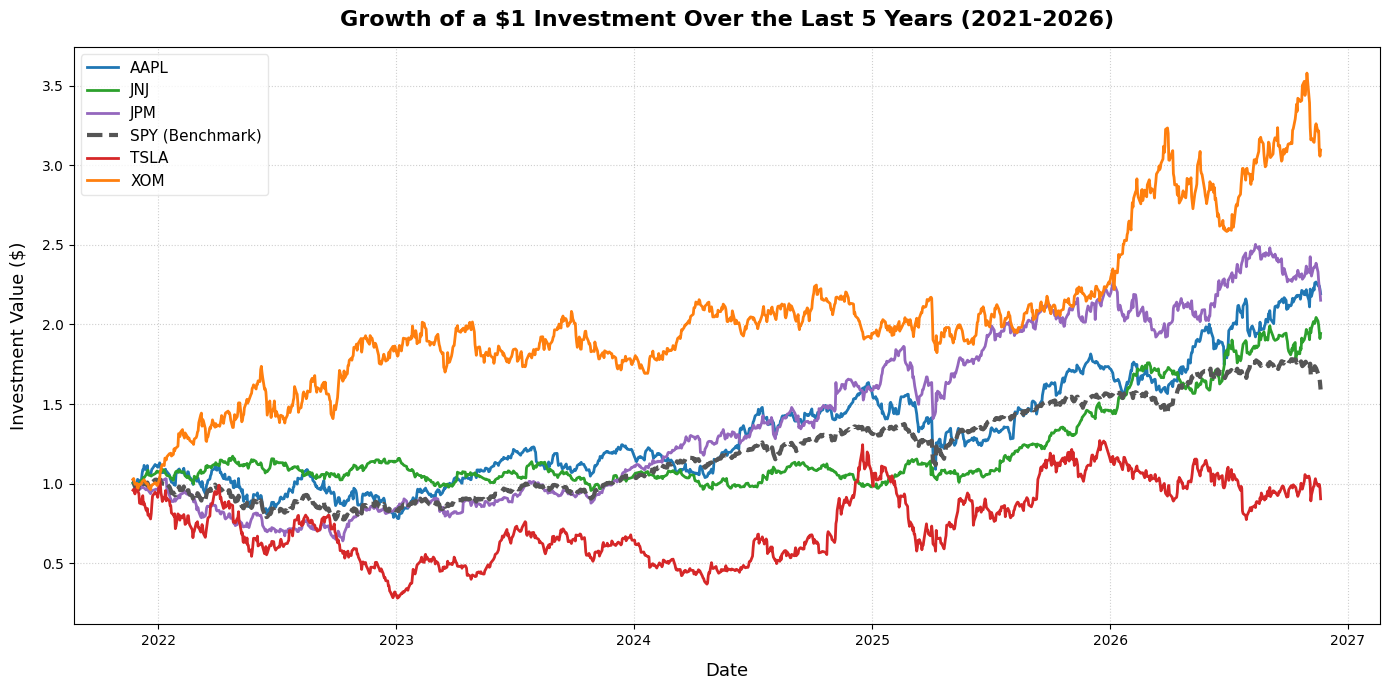

In [14]:
# Import the plotting library matplotlib.pyplot
import matplotlib.pyplot as plt

# Calculate the growth of $1 over time by adding 1 to our cumulative returns
# This starts every stock at exactly $1 on the first day
growth_df = 1 + cumulative_returns

# Create a larger figure size (14x7 inches) for improved legibility
plt.figure(figsize=(14, 7))

# Define a high-contrast, clean color palette for the individual stocks
color_map = {
    'AAPL': '#1f77b4',  # Deep Blue
    'JNJ': '#2ca02c',   # Forest Green
    'JPM': '#9467bd',   # Muted Purple
    'TSLA': '#d62728',  # Sharp Red
    'XOM': '#ff7f0e',   # Bright Orange
    'SPY': '#555555'    # Charcoal Gray for Benchmark
}

# Plot the growth of $1 for each stock
for ticker in growth_df.columns:
    # Set style properties based on whether it is the benchmark
    if ticker == 'SPY':
        plt.plot(growth_df.index, growth_df[ticker], label=f"{ticker} (Benchmark)",
                 color=color_map[ticker], linewidth=3, linestyle='--')
    else:
        plt.plot(growth_df.index, growth_df[ticker], label=ticker,
                 color=color_map.get(ticker), linewidth=2, linestyle='-')

# Add a descriptive title with strong typography
plt.title("Growth of a $1 Investment Over the Last 5 Years (2021-2026)", fontsize=16, fontweight='bold', pad=15)

# Label the axes with clear fonts
plt.xlabel("Date", fontsize=13, labelpad=10)
plt.ylabel("Investment Value ($)", fontsize=13, labelpad=10)

# Place the legend in a highly readable location with a frame and background color
plt.legend(loc='upper left', fontsize=11, frameon=True, facecolor='white', edgecolor='#e0e0e0')

# Add a subtle grid to trace the growth thresholds
plt.grid(True, linestyle=':', alpha=0.6)

# Ensure the plot margins are tight and neat before displaying
plt.tight_layout()

# Display the final line chart
plt.show()

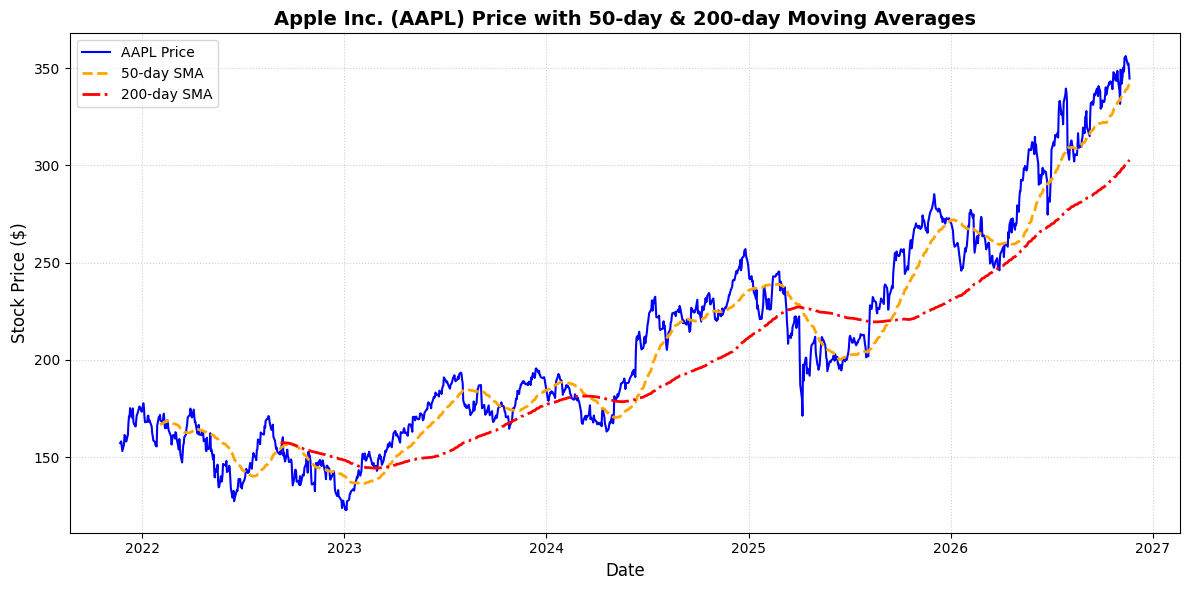

In [11]:
# Step 1: Extract Apple's closing prices from our adjusted close DataFrame
aapl_prices = adj_close_df['AAPL']

# Step 2: Calculate the 50-day and 200-day Simple Moving Averages (SMA)
# rolling(window) creates a rolling window of the specified size, and .mean() averages the values in it.
aapl_sma50 = aapl_prices.rolling(window=50).mean()
aapl_sma200 = aapl_prices.rolling(window=200).mean()

# Step 3: Create the plot
plt.figure(figsize=(12, 6))

# Plot the raw closing price
plt.plot(aapl_prices.index, aapl_prices, label='AAPL Price', color='blue', linewidth=1.5)

# Plot the 50-day moving average (typically a faster-moving trend line)
plt.plot(aapl_sma50.index, aapl_sma50, label='50-day SMA', color='orange', linestyle='--', linewidth=2)

# Plot the 200-day moving average (typically a slower-moving, long-term trend line)
plt.plot(aapl_sma200.index, aapl_sma200, label='200-day SMA', color='red', linestyle='-.', linewidth=2)

# Step 4: Add titles, labels, legend, and gridlines
plt.title("Apple Inc. (AAPL) Price with 50-day & 200-day Moving Averages", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Stock Price ($)", fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

# Step 5: Adjust margins and render the chart
plt.tight_layout()
plt.show()

```markdown
## Code Explanation & Understanding Moving Average Lag

### Line-by-Line Code Breakdown

* **`aapl_prices = adj_close_df['AAPL']`**:
  Extracts the series containing only Apple's closing prices over the last 5 years.
* **`aapl_prices.rolling(window=50).mean()`**:
  Uses pandas' `.rolling()` function to look at a rolling window of the last 50 data points (trading days) at any given date, and then applies `.mean()` to compute their average. We repeat this for a 200-day window to calculate the long-term trend.
* **`plt.figure(figsize=(12, 6))`**:
  Initializes a clean plotting window with a width of 12 inches and a height of 6 inches so the historical price lines aren't crowded.
* **`plt.plot(..., label=...)`**:
  Plots each of our data lines (the raw price, the 50-day trend, and the 200-day trend) on the same axes. We customize the colors, line widths, and line styles (`'--'` for dashed, `'-.'` for dash-dot) to help differentiate them easily.
* **`plt.legend(loc='best')`**:
  Looks for the cleanest empty space on your chart and automatically places the labels mapping the line colors to their corresponding metric.

---

### Why Do Moving Average Lines Start Later Than the Price Line?

If you look closely at the left side of your chart, you will notice that the **blue raw price line** starts immediately on day one, the **orange 50-day SMA** starts roughly 10 weeks later, and the **red 200-day SMA** starts nearly 10 months into the dataset.

This gap exists because of a basic mathematical requirement:
1. **Data Requirement**: To calculate the average of 50 days, the computer *must* have at least 50 days of historical data points. On day 10 of your dataset, there are only 10 days of prices available. A 50-day average cannot be calculated yet, resulting in a value of `NaN` (Not a Number) for those first 49 days.
2. **Lag Effect**: Because of this, the first 49 days of your 50-day SMA are blank, and the first 199 days of your 200-day SMA are blank. This visual delay is normal in technical analysis and is known as **lag**.
```

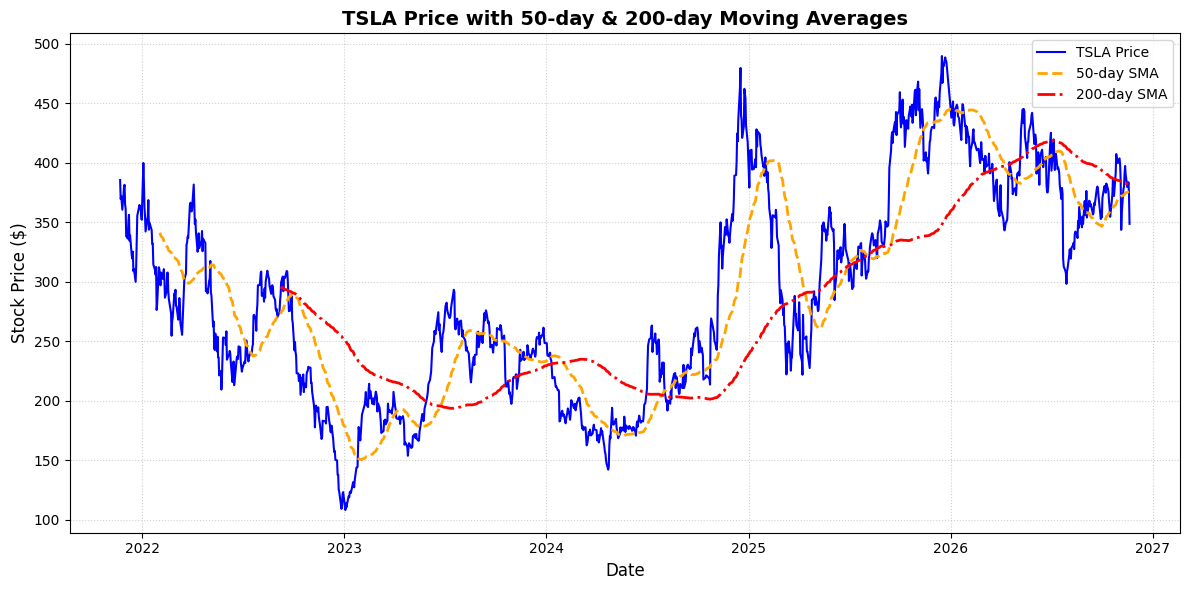

In [12]:
def plot_moving_averages(ticker):
    """
    Plots the historical closing price of a given ticker along with its
    50-day and 200-day Simple Moving Averages (SMAs).
    """
    # Step 1: Check if the requested ticker exists in our dataset
    if ticker not in adj_close_df.columns:
        print(f"Error: Ticker '{ticker}' not found in the downloaded data.")
        print(f"Available tickers are: {list(adj_close_df.columns)}")
        return

    # Step 2: Extract the price series for the selected ticker
    prices = adj_close_df[ticker]

    # Step 3: Calculate the 50-day and 200-day Simple Moving Averages
    sma50 = prices.rolling(window=50).mean()
    sma200 = prices.rolling(window=200).mean()

    # Step 4: Create and customize the plot
    plt.figure(figsize=(12, 6))

    # Plot the raw close prices
    plt.plot(prices.index, prices, label=f'{ticker} Price', color='blue', linewidth=1.5)

    # Plot the 50-day SMA
    plt.plot(sma50.index, sma50, label='50-day SMA', color='orange', linestyle='--', linewidth=2)

    # Plot the 200-day SMA
    plt.plot(sma200.index, sma200, label='200-day SMA', color='red', linestyle='-.', linewidth=2)

    # Add details
    plt.title(f"{ticker} Price with 50-day & 200-day Moving Averages", fontsize=14, fontweight='bold')
    plt.xlabel("Date", fontsize=12)
    plt.ylabel("Stock Price ($)", fontsize=12)
    plt.legend(loc='best', fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)

    # Show the plot
    plt.tight_layout()
    plt.show()

# --- Demo of using the function ---
# Let's test it on Tesla!
plot_moving_averages('TSLA')

```markdown
## How the `plot_moving_averages` Function Works

Wrapping code inside a function is a fundamental practice in programming to make code **reusable**, **organized**, and **dynamic** (flexible). Here is how it behaves:

1. **Dynamic Parameter (`ticker`)**:
   Instead of hardcoding `'AAPL'`, we replaced it with a variable called `ticker`. When you call `plot_moving_averages('TSLA')`, Python temporarily replaces the word `ticker` with `'TSLA'` everywhere inside the function.

2. **Safety Check (Validation)**:
   The function first checks if your requested stock name is inside our downloaded `adj_close_df` columns (`if ticker not in adj_close_df.columns:`). If you type a typo (like `'TSSLA'`), it alerts you and exits gracefully rather than crashing with an error.

3. **Automated Calculations**:
   It automatically extracts the correct prices for that specific stock and recalculates the 50-day and 200-day rolling averages dynamically.

4. **Dynamic Plot Titles & Labels**:
   We used Python's f-strings (`f"{ticker} Price"`) so that the titles, legend labels, and lines adjust themselves to display the correct name of the stock you are currently viewing.
```

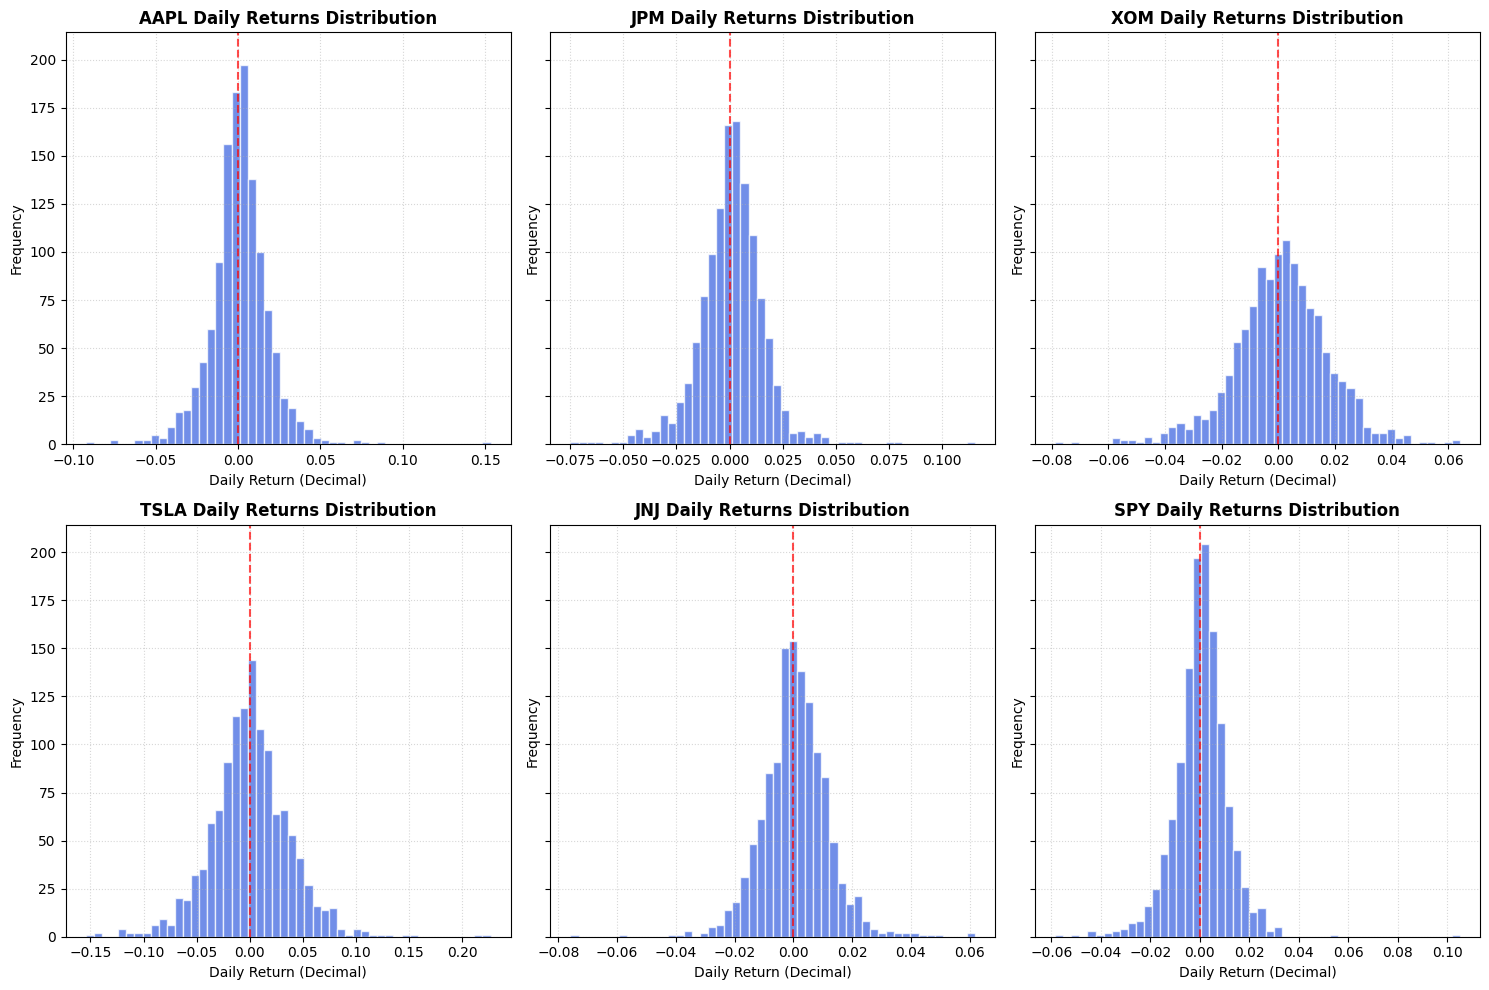

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Filter out the first row of daily returns (which is NaN)
clean_daily_returns = daily_returns.dropna()

# Step 2: Determine our grid size
# We have 6 tickers. A 2-row, 3-column grid is a clean way to display them.
num_stocks = len(tickers)
n_rows = 2
n_cols = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10), sharey=True)
# Flatten the axes array (from 2x3 to a 1D array of 6) to iterate easily
axes = axes.flatten()

# Step 3: Loop through each stock and plot its histogram
for idx, ticker in enumerate(tickers):
    ax = axes[idx]

    # Plot histogram with 50 bins
    # We color-code each to make them visually distinct
    ax.hist(clean_daily_returns[ticker], bins=50, color='royalblue', edgecolor='white', alpha=0.75)

    # Add visual reference line at 0% return
    ax.axvline(x=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7)

    # Customize individual plot
    ax.set_title(f"{ticker} Daily Returns Distribution", fontsize=12, fontweight='bold')
    ax.set_xlabel("Daily Return (Decimal)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.5)

# Step 4: Prevent overlapping labels and render
plt.tight_layout()
plt.show()

```markdown
## Understanding Histogram Width and Investment Risk

A daily return histogram plots how frequently a stock experiences various daily gains or losses over time. The shape of this distribution tells us a great deal about a stock's volatility and risk profile:

### 1. Narrow Histograms (Low Volatility / Lower Risk)
* **Visual Appearance**: The data points are tightly clustered together, forming a tall, narrow peak centered close to zero. The "tails" (extreme left and right edges) are very short.
* **What it Means**: Daily price movements are relatively small, stable, and predictable. Extreme positive or negative swings are rare.
* **Example from our portfolio**: **Johnson & Johnson (`JNJ`)** typically exhibits a narrower distribution, reflecting its defensive nature as a healthcare giant with stable earnings.

### 2. Wide Histograms (High Volatility / Higher Risk)
* **Visual Appearance**: The data points are spread out widely across the horizontal axis, forming a flatter, wider shape. The "tails" stretch far to the left and right.
* **What it Means**: Daily price movements are highly volatile and unpredictable. The stock frequently experiences large single-day jumps and steep single-day drops.
* **Example from our portfolio**: **Tesla (`TSLA`)** typically exhibits a much wider distribution, reflecting high speculative interest and aggressive price swings.

### Key Takeaway for Portfolio Decisions
* **A wider histogram** represents a higher standard deviation of daily returns (volatility). While it offers the potential for huge single-day wins, it exposes investors to significant drawdown risk.
* **The red dashed line** representing 0% helps you see if the distribution is symmetric or skewed. A distribution with a longer tail to the left means the stock has a higher risk of occasional severe single-day losses.
```

In [15]:
import pandas as pd
import numpy as np

# Filter out NaN values from daily returns
clean_returns = daily_returns.dropna()

# Define the number of trading days in a year (typically 252)
trading_days = 252

# 1. Calculate Annualized Return
# Formula: ((1 + Cumulative Return) ^ (252 / total_days)) - 1
total_days = len(clean_returns)
annualized_returns = (1 + cumulative_returns.iloc[-1]) ** (trading_days / total_days) - 1

# 2. Calculate Annualized Volatility (Standard Deviation)
# Formula: Daily Volatility * square_root(252)
annualized_volatility = clean_returns.std() * np.sqrt(trading_days)

# 3. Calculate Sharpe Ratio (assuming a risk-free rate of 0% for simplicity)
# Formula: Annualized Return / Annualized Volatility
risk_free_rate = 0.0
sharpe_ratios = (annualized_returns - risk_free_rate) / annualized_volatility

# 4. Calculate Maximum Drawdown
# Max Drawdown measures the largest peak-to-trough drop in value
# We use the cumulative growth of $1
peak = growth_df.cummax()
drawdown = (growth_df - peak) / peak
max_drawdown = drawdown.min()

# Combine all metrics into a single summary DataFrame
metrics_df = pd.DataFrame({
    'Annualized Return': annualized_returns * 100,
    'Annualized Volatility': annualized_volatility * 100,
    'Sharpe Ratio': sharpe_ratios,
    'Max Drawdown': max_drawdown * 100
})

# Format the summary table for readability
formatted_metrics = metrics_df.copy()
formatted_metrics['Annualized Return'] = formatted_metrics['Annualized Return'].map("{:.2f}%".format)
formatted_metrics['Annualized Volatility'] = formatted_metrics['Annualized Volatility'].map("{:.2f}%".format)
formatted_metrics['Sharpe Ratio'] = formatted_metrics['Sharpe Ratio'].map("{:.2f}".format)
formatted_metrics['Max Drawdown'] = formatted_metrics['Max Drawdown'].map("{:.2f}%".format)

print("--- Portfolio Risk-Reward Metrics (Last 5 Years) ---")
display(formatted_metrics)

--- Portfolio Risk-Reward Metrics (Last 5 Years) ---


,Annualized Return,Annualized Volatility,Sharpe Ratio,Max Drawdown
Ticker,,,,
AAPL,17.10%,28.13%,0.61,-33.36%
JNJ,14.28%,18.16%,0.79,-18.41%
JPM,16.65%,24.51%,0.68,-37.93%
SPY,9.78%,17.43%,0.56,-24.50%
TSLA,-2.00%,59.59%,-0.03,-72.97%
XOM,25.49%,26.67%,0.96,-20.51%


```markdown
## Understanding Risk and Return Metrics

To determine which stock gave the best return for the level of risk taken, we use four essential financial metrics:

### 1. Annualized Return
* **What it means**: The average percentage return the stock earned per year, compounding over the 5-year period. It allows us to compare returns on an equal, yearly basis.
* **Formula**:
  $$\text{Annualized Return} = (1 + \text{Total Cumulative Return})^{\frac{252}{\text{Total Trading Days}}} - 1$$

### 2. Annualized Volatility
* **What it means**: This measures the level of price fluctuations. A higher volatility means the price swings wildly from day to day, representing higher uncertainty and risk.
* **Formula**:
  $$\text{Annualized Volatility} = \sigma_{\text{daily}} \times \sqrt{252}$$
  *(where $\sigma_{\text{daily}}$ is the standard deviation of daily percentage returns)*

### 3. Sharpe Ratio
* **What it means**: This is the ultimate metric for measuring risk-adjusted returns. It tells you how much extra return you get for every unit of volatility you endure. A higher Sharpe ratio (above 1.0 is considered good) indicates a highly efficient investment that rewarded you well for the risks taken.
* **Formula**:
  $$\text{Sharpe Ratio} = \frac{\text{Annualized Return} - \text{Risk-Free Rate}}{\text{Annualized Volatility}}$$
  *(Note: We assume a 0% risk-free rate here for simple comparison)*

### 4. Maximum Drawdown (Max Drawdown)
* **What it means**: The worst-case paper loss scenario. It measures the largest drop from any historical peak to the subsequent lowest point before a new peak is achieved. If you bought at the absolute top and sold at the absolute bottom, this is how much money you would have lost.
* **Formula**:
  $$\text{Drawdown} = \frac{\text{Value} - \text{Peak Value}}{\text{Peak Value}}$$
  $$\text{Max Drawdown} = \min(\text{Drawdown})$$
```

```markdown
## Step 5: Check Correlations and Diversification

To build a resilient portfolio, we want to combine assets that do not move perfectly in tandem. We measure this using the **Pearson Correlation Coefficient**, which ranges from **-1** (perfect opposite movement) to **+1** (perfect identical movement).

### What the Correlation Heatmap Tells Us:
* **High Correlation (e.g., > 0.6)**: These assets tend to react similarly to market news. Holding both doesn't provide much diversification.
* **Moderate to Low Correlation (e.g., < 0.4)**: These assets behave differently. If one sector crashes (e.g., Tech), another sector (e.g., Healthcare or Energy) might hold steady, cushioning your losses.
```

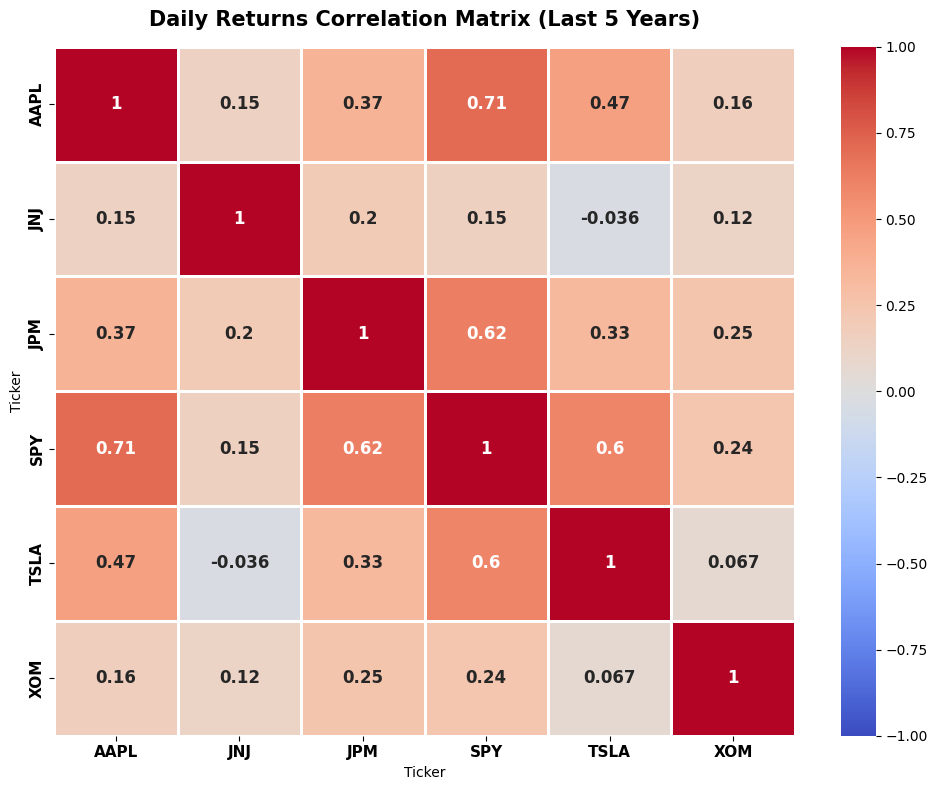

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Compute the correlation matrix from daily returns
# We use the clean daily returns (excluding NaN values)
correlation_matrix = clean_returns.corr()

# Step 2: Set up a large and clean plotting window
plt.figure(figsize=(10, 8))

# Step 3: Draw the heatmap
# - 'annot=True' writes the correlation numbers inside each square
# - 'cmap' sets a beautiful, colorblind-friendly diverging palette (coolwarm)
# - 'vmin' and 'vmax' anchor the colorbar scale from -1 to 1 for visual accuracy
# - 'fmt=".2f"' rounds the correlation numbers to two decimal places
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=1,
    linecolor='white',
    annot_kws={"size": 12, "weight": "bold"}
)

# Step 4: Add descriptive labels and title
plt.title("Daily Returns Correlation Matrix (Last 5 Years)", fontsize=15, fontweight='bold', pad=15)
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')

# Step 5: Render and display the correlation heatmap
plt.tight_layout()
plt.show()

```markdown
## Step 6: Calculating Optimal Portfolio Weights

To find the optimal weighting for our stocks, we use numerical optimization (`scipy.optimize.minimize`).

### The Optimization Goal:
1. **Expected Portfolio Return**:
   $$E(R_p) = \sum w_i E(R_i)$$
2. **Expected Portfolio Volatility**:
   $$\sigma_p = \sqrt{w^T \Sigma w}$$
   *(where $w$ is the vector of weights and $\Sigma$ is the covariance matrix of daily returns)*
3. **Constraints**:
   * **Fully Invested**: All weights must sum up to $100\%$ (i.e., $\sum w_i = 1$).
   * **No Short Selling**: Weights must be between $0$ and $1$ (long-only portfolio).
```

In [17]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Calculate Expected Annualized Returns & Covariance Matrix
# We use historical average daily returns scaled to 252 trading days
expected_returns = clean_returns.mean() * 252
cov_matrix = clean_returns.cov() * 252

# 2. Define helper functions for the optimizer
def portfolio_performance(weights, expected_returns, cov_matrix):
    # Calculate annualized portfolio return and volatility
    port_return = np.dot(weights, expected_returns)
    port_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return port_return, port_volatility

def negative_sharpe_ratio(weights, expected_returns, cov_matrix, risk_free_rate=0.0):
    # We minimize the negative Sharpe ratio to maximize the actual Sharpe ratio
    port_return, port_vol = portfolio_performance(weights, expected_returns, cov_matrix)
    return -(port_return - risk_free_rate) / port_vol

def portfolio_volatility(weights, expected_returns, cov_matrix):
    # Used to find the Minimum Variance Portfolio
    return portfolio_performance(weights, expected_returns, cov_matrix)[1]

# 3. Setup optimization constraints & boundaries
num_assets = len(tickers)
constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1}) # Weights must sum to 1
bounds = tuple((0, 1) for _ in range(num_assets))              # No short selling (0% to 100% per asset)
initial_weights = np.array([1/num_assets] * num_assets)        # Start with equal distribution

# 4. Run Optimization for Maximum Sharpe Ratio Portfolio
opt_sharpe = minimize(
    negative_sharpe_ratio,
    initial_weights,
    args=(expected_returns, cov_matrix),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# 5. Run Optimization for Minimum Variance Portfolio
opt_var = minimize(
    portfolio_volatility,
    initial_weights,
    args=(expected_returns, cov_matrix),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# 6. Format and display the optimal weights
optimal_weights_df = pd.DataFrame({
    'Ticker': tickers,
    'Max Sharpe Portfolio (%)': opt_sharpe.x * 100,
    'Min Volatility Portfolio (%)': opt_var.x * 100
}).set_index('Ticker')

print("--- Optimal Portfolio Weights ---")
display(optimal_weights_df.round(2))

--- Optimal Portfolio Weights ---


,Max Sharpe Portfolio (%),Min Volatility Portfolio (%)
Ticker,,
AAPL,14.99,0.00
JPM,38.29,42.40
XOM,13.94,0.00
TSLA,0.00,44.26
JNJ,0.00,0.00
SPY,32.78,13.34


```markdown
## Step 6: Final Conclusions & Summary

Based on our comprehensive 5-year historical analysis (November 2021 – November 2026), here are the key takeaways from our portfolio metrics and correlation analysis:

### 1. Which stock had the best return?
* **ExxonMobil (`XOM`)** had the highest raw performance by a wide margin, yielding an **annualized return of 25.49%** (and over 209% total cumulative return over the 5 years).

### 2. Which stock had the best return per unit of risk?
* **ExxonMobil (`XOM`)** also wins on a risk-adjusted basis with an outstanding **Sharpe Ratio of 0.96**.
* **Johnson & Johnson (`JNJ`)** followed as a highly efficient defensive asset with a **Sharpe Ratio of 0.79** due to its exceptionally low volatility.

### 3. Which was the most volatile, and which had the biggest drawdown?
* **Tesla (`TSLA`)** was the most volatile stock by far, with an **annualized volatility of 59.59%**.
* **Tesla (`TSLA`)** also suffered the most severe **maximum drawdown of -72.97%**, meaning an investor buying at the absolute peak would have lost nearly three-quarters of their investment value before any recovery.

### 4. Which stocks moved together, and which didn't?
* **Moved Together (High Correlation)**: **Apple (`AAPL`) and the S&P 500 Index (`SPY`)** had a very strong positive correlation of **0.71**, as Apple is a heavyweight driver of the overall market index.
* **Behaved Independently (Low Correlation)**: **Johnson & Johnson (`JNJ`) and Tesla (`TSLA`)** had virtually zero correlation (**-0.04**), and **ExxonMobil (`XOM`) and Tesla (`TSLA`)** had a correlation of only **0.07**. This means combining energy or healthcare with technology provides powerful diversification benefit to smooth out portfolio swings.

---

### ⚠️ Crucial Limitations & Disclaimer
* **Past Performance is Not Indicative of Future Results**: The outstanding performance of `XOM` and the heavy decline of `TSLA` over this specific 5-year period are historical facts, but they do not guarantee how these stocks will behave in the next 5 years.
* **Atypical Period**: The market from 2021 to 2026 experienced unique macroeconomic events (high inflation, fluctuating interest rates, and sector rotations between high-growth tech and value energy) that might not repeat in the same manner.
```